<img src="https://www.fct.unl.pt/sites/default/files/imagens/departamentos/logos/pt_df_rgb_positivo_h.png" width="250" />

## *Métodos de Imagem Médica - MIM*

**Projeto realizado por:** Guilherme Leiria (N.º 70783) e Rafael Gonçalves (N.º 71250)

**Docente:** Professora Ana Rita Londral

**Data:** 25/11/2026

---

# 📃 **DIPY Estudo | "The energetic costs of the human connectome"**

A **ressonância magnética de difusão** (*dMRI*) é uma técnica de imagem médica que permite estudar o movimento das moléculas de água nos tecidos biológicos, fornecendo informações sobre a organização da **substância branca cerebral**. Através de métodos computacionais como a *tractografia*, torna-se possível estimar trajetórias tridimensionais associadas aos principais feixes de fibras nervosas.

O presente **Jupyter Notebook** tem como objetivo aplicar algumas das funcionalidades da biblioteca **DIPY — Diffusion Imaging in Python** a dados reais provenientes do **estudo científico** *«An energy costly architecture of neuromodulators for human brain evolution and cognition»*, de Castrillon et al. (2023). Para esta experiência, foi selecionado um participante saudável (`sub-s028`), cujos dados se encontram disponíveis no repositório [**OpenNeuro — ds004513**](https://openneuro.org/datasets/ds004513).

Tal como no demonstrador original, serão aplicados os modelos **DTI** (*Diffusion Tensor Imaging*) e **CSA** (*Constant Solid Angle*) para analisar a difusão da água, calcular mapas de anisotropia e reconstruir trajetórias da substância branca através do algoritmo **EuDX**. Posteriormente, será avaliada a influência de diferentes limiares de **anisotropia fracionária generalizada (GFA)** no número e comprimento das trajetórias reconstruídas, recorrendo a gráficos comparativos e visualizações **3D estáticas e interativas**.

> **Objetivo final:** Demonstrar a aplicação prática do DIPY a dados reais de investigação científica, explorando as potencialidades da biblioteca no processamento de imagens médicas e na reconstrução de trajetórias cerebrais. Esta experiência constitui uma aplicação didática inspirada no estudo, não uma reprodução integral da metodologia dos autores.

## **Bibliotecas e Configuração Inicial**

- Importação das bibliotecas necessárias, definição dos parâmetros da experiência e apresentação das versões do Python e das bibliotecas utilizadas.

In [1]:
# libraries
from pathlib import Path
from importlib.metadata import version
from IPython.display import display
from urllib.parse import quote
from urllib.request import urlopen, urlretrieve
import xml.etree.ElementTree as ET
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib

from dipy.data import default_sphere
from dipy.core.gradients import gradient_table
from dipy.io.gradients import read_bvals_bvecs
from dipy.io.image import load_nifti
from dipy.segment.mask import median_otsu
from dipy.reconst.dti import TensorModel
from dipy.reconst.shm import CsaOdfModel
from dipy.direction import peaks_from_model
from dipy.tracking import utils
from dipy.tracking.stopping_criterion import ThresholdStoppingCriterion
from dipy.tracking.tracker import eudx_tracking
from dipy.tracking.streamline import Streamlines, length

plt.rcParams["figure.dpi"] = 110

DATASET = "ds004513"
SUJEITO = "sub-s028"
SESSAO = "ses-open"
PASTA_DADOS = Path("ds004513") / SUJEITO / SESSAO / "dwi"

LIMIAR_FA = 0.25
PERCENTIS_GFA = [20, 40, 60]
MAX_SEMENTES = 400
SEMENTE_ALEATORIA = 2026
DENSIDADE_SEMENTES = [1, 1, 1]
PASSO_MM = 0.5
ANGULO_MAX_GRAUS = 60
COMPRIMENTO_MIN_MM = 10.0
COMPRIMENTO_MAX_MM = 200.0

print("python:", sys.version.split()[0])
print("===============")
for pacote in ("dipy", "numpy", "pandas", "matplotlib", "nibabel", "scipy", "plotly"):
    print(f"{pacote}: {version(pacote)}")

python: 3.13.2
dipy: 1.12.1
numpy: 2.5.4
pandas: 3.1.1
matplotlib: 3.10.1
nibabel: 5.4.2
scipy: 1.18.1
plotly: 7.1.0


## **Carregamento do Dataset ds004513**

- Obtenção dos ficheiros DWI, b-values e b-vectors do participante selecionado, carregamento da MRI, preparação dos gradientes e criação de uma máscara cerebral aproximada.

In [2]:
# dataset ds004513
ficheiros = sorted(PASTA_DADOS.glob("*_dwi.nii.gz"))

if not ficheiros:
    raise FileNotFoundError("Não foram encontrados ficheiros DWI na pasta indicada.")

dwi_path = ficheiros[0]
bvals_path = dwi_path.with_name(dwi_path.name.replace(".nii.gz", ".bval"))
bvecs_path = dwi_path.with_name(dwi_path.name.replace(".nii.gz", ".bvec"))


dwi, affine = load_nifti(str(dwi_path))

bvals, bvecs = read_bvals_bvecs(str(bvals_path), str(bvecs_path))
gtab = gradient_table(bvals, bvecs=bvecs)


b0 = np.mean(dwi[..., gtab.b0s_mask], axis=-1)

_, brain_mask = median_otsu(b0, median_radius=4, numpass=3, dilate=1)
brain_mask = brain_mask.astype(bool)


orientacao = nib.aff2axcodes(affine)

eixo_lr = next(i for i, letra in enumerate(orientacao) if letra in ("L", "R"))
eixo_si = next(i for i, letra in enumerate(orientacao) if letra in ("S", "I"))


print("Participante:", SUJEITO)
print("Dimensões DWI:", dwi.shape)
print("Dimensões do voxel:", np.round(nib.affines.voxel_sizes(affine), 2), "mm")
print("Orientação:", orientacao)
print("Volumes b0:", gtab.b0s_mask.sum())
print("Volumes com difusão:", (~gtab.b0s_mask).sum())
print("Valores de b (s/mm²):", np.unique(np.round(bvals / 100) * 100))
print("Voxels da máscara cerebral:", brain_mask.sum())

Participante: sub-s028
Dimensões DWI: (130, 132, 60, 31)
Dimensões do voxel: [2. 2. 2.] mm
Orientação: ('L', 'A', 'S')
Volumes b0: 1
Volumes com difusão: 30
Valores de b (s/mm²): [  0. 800.]
Voxels da máscara cerebral: 197486


## **Visualização das Imagens de MRI**

- Visualização dos cortes axial e sagital da MRI de referência e identificação da substância branca através da sobreposição da respetiva máscara.

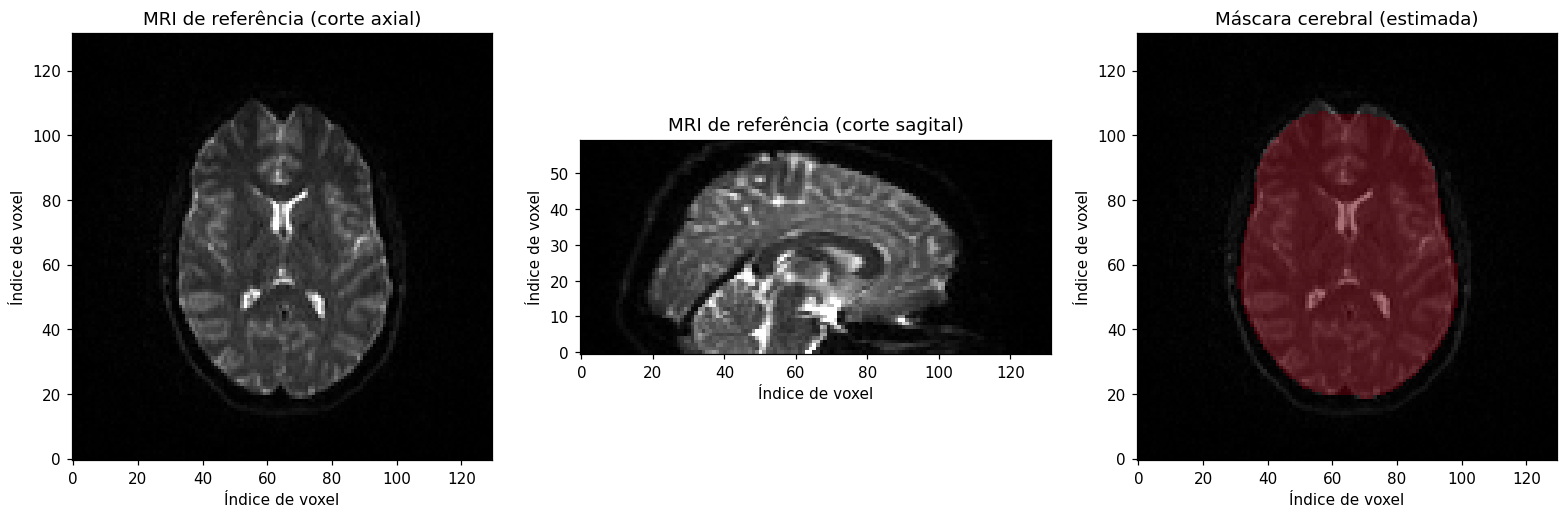

In [3]:
xi = int(np.median(np.where(brain_mask)[eixo_lr]))
zi = int(np.median(np.where(brain_mask)[eixo_si]))

imagem_axial = np.take(b0, zi, axis=eixo_si).T
mascara_axial = np.take(brain_mask, zi, axis=eixo_si).T
intensidade_max = np.percentile(b0[brain_mask], 99.5)

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.6), constrained_layout=True)

axes[0].imshow(imagem_axial, cmap="gray", origin="lower", vmin=0, vmax=intensidade_max)
axes[0].set_title("MRI de referência (corte axial)")

axes[1].imshow(np.take(b0, xi, axis=eixo_lr).T, cmap="gray", origin="lower", vmin=0, vmax=intensidade_max)
axes[1].set_title("MRI de referência (corte sagital)")

axes[2].imshow(imagem_axial, cmap="gray", origin="lower", vmin=0, vmax=intensidade_max)
axes[2].imshow(np.ma.masked_equal(mascara_axial, 0), cmap="Reds", alpha=0.56, origin="lower", vmin=0, vmax=1)
axes[2].set_title("Máscara cerebral (estimada)")

for ax in axes:
    ax.set_xlabel("Índice de voxel")
    ax.set_ylabel("Índice de voxel")
    ax.set_aspect("equal")

plt.show()

## **Análise da Difusão através do Modelo DTI**

- Aplicação do modelo de tensor de difusão (DTI) para calcular e visualizar os mapas de anisotropia fracionária (FA) e difusividade média (MD), incluindo os respetivos valores medianos na substância branca.

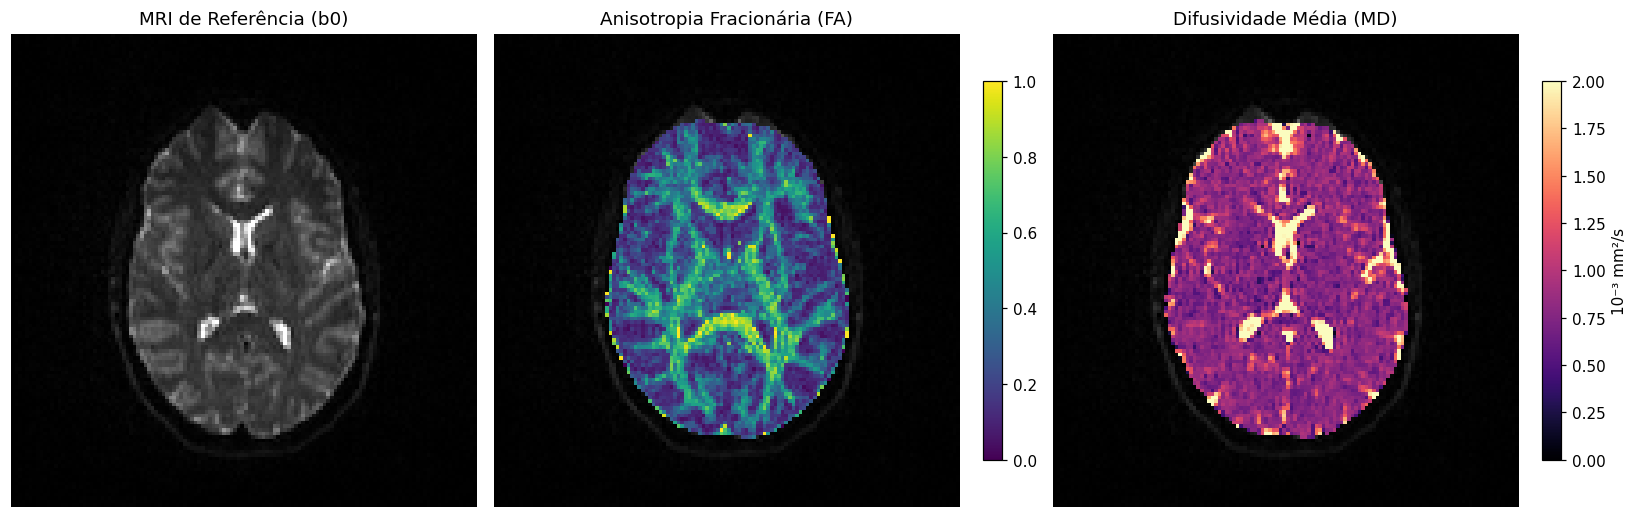

FA mediana: 0.269
MD mediana: 0.817 × 10⁻³ mm²/s
Voxels na máscara aproximada de substância branca: 105885


In [4]:
model_dti = TensorModel(gtab)
fit_dti = model_dti.fit(dwi, mask=brain_mask)

fa = np.clip(np.nan_to_num(fit_dti.fa, nan=0, posinf=0, neginf=0), 0, 1)
md = np.maximum(np.nan_to_num(fit_dti.md, nan=0, posinf=0, neginf=0), 0)

white_matter = brain_mask & (fa >= LIMIAR_FA)
if not white_matter.any():
    raise ValueError("A máscara estimada de substância branca ficou vazia.")

fa_axial = np.ma.masked_where(~mascara_axial, np.take(fa, zi, axis=eixo_si).T)
md_axial = np.ma.masked_where(~mascara_axial, np.take(md, zi, axis=eixo_si).T * 1000)

fig, axes = plt.subplots(1, 3, figsize=(14.8, 4.6), constrained_layout=True)

for ax in axes:
    ax.imshow(imagem_axial, cmap="gray", origin="lower", vmin=0, vmax=intensidade_max)
    ax.axis("off")

axes[0].set_title("MRI de Referência (b0)")

im_fa = axes[1].imshow(fa_axial, cmap="viridis", origin="lower", vmin=0, vmax=1)
axes[1].set_title("Anisotropia Fracionária (FA)")
fig.colorbar(im_fa, ax=axes[1], shrink=0.8)

im_md = axes[2].imshow(md_axial, cmap="magma", origin="lower", vmin=0, vmax=2)
axes[2].set_title("Difusividade Média (MD)")
fig.colorbar(im_md, ax=axes[2], shrink=0.8, label="10⁻³ mm²/s")

plt.show()

print(f"FA mediana: {np.median(fa[brain_mask]):.3f}")
print(f"MD mediana: {1000 * np.median(md[brain_mask]):.3f} × 10⁻³ mm²/s")
print("Voxels na máscara aproximada de substância branca:", int(white_matter.sum()))

## **Análise da Difusão através do Modelo CSA**

- Aplicação do modelo CSA para estimar as orientações de difusão, calcular e visualizar o mapa de anisotropia generalizada (GFA) e comparar diferentes limiares de GFA na substância branca.

GFA — percentis P10/P50/P90: [0.267 0.406 0.726]
Limiares GFA (P20/P40/P60): [0.3024, 0.37, 0.448]


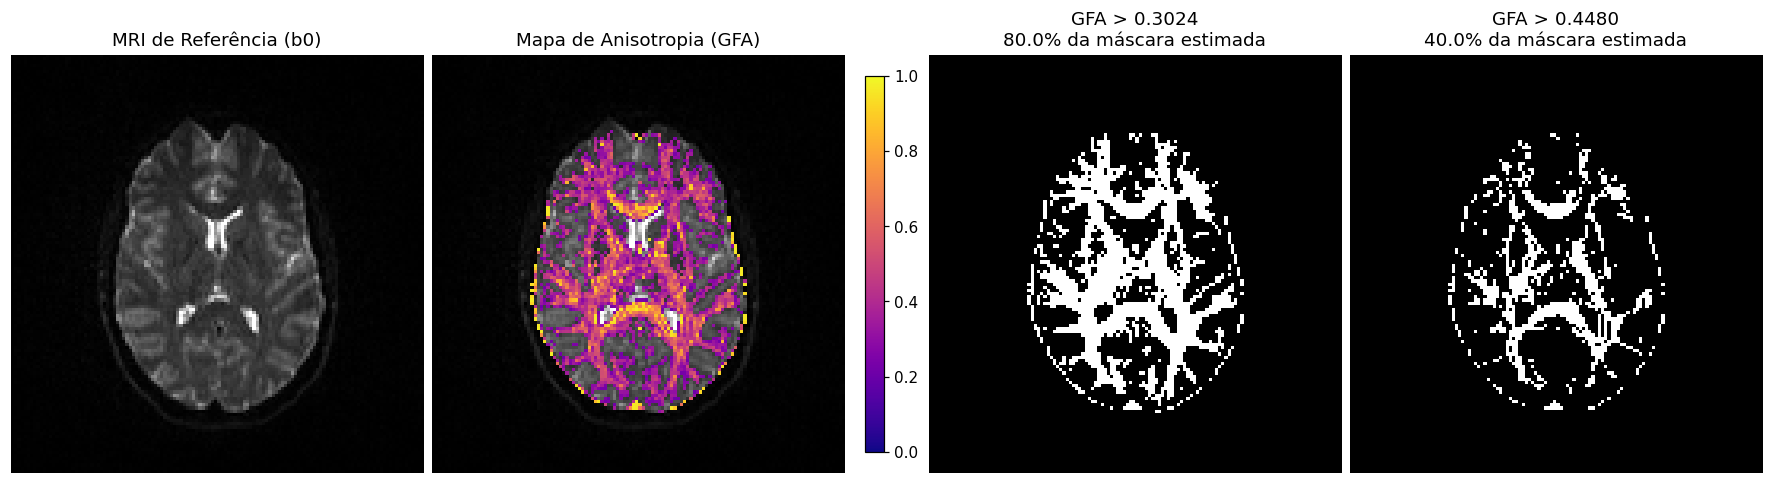

In [5]:
csa_model = CsaOdfModel(gtab, sh_order_max=4)
csa_peaks = peaks_from_model(csa_model, dwi, default_sphere, relative_peak_threshold=0.8, min_separation_angle=45, mask=white_matter)

gfa = np.clip(np.nan_to_num(csa_peaks.gfa, nan=0, posinf=0, neginf=0), 0, 1)
valores_gfa = gfa[white_matter]

LIMIARES_GFA = np.round(np.percentile(valores_gfa, PERCENTIS_GFA), 4).tolist()

LIMIAR_REFERENCIA = LIMIARES_GFA[1]
CORES_LIMIARES = dict(zip(LIMIARES_GFA, ["#237aa6", "#d68b27", "#8e5db7"]))

print("GFA — percentis P10/P50/P90:", np.round(np.percentile(valores_gfa, [10, 50, 90]), 3))
print("Limiares GFA (P20/P40/P60):", LIMIARES_GFA)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), constrained_layout=True)

axes[0].imshow(imagem_axial, cmap="gray", origin="lower", vmin=0, vmax=intensidade_max)
axes[0].set_title("MRI de Referência (b0)")
axes[1].imshow(imagem_axial, cmap="gray", origin="lower", vmin=0, vmax=intensidade_max)

gfa_axial = np.ma.masked_where(~np.take(white_matter, zi, axis=eixo_si).T,
                               np.take(gfa, zi, axis=eixo_si).T)
im = axes[1].imshow(gfa_axial, cmap="plasma", origin="lower", vmin=0, vmax=1)
axes[1].set_title("Mapa de Anisotropia (GFA)")
fig.colorbar(im, ax=axes[1], shrink=0.8)

for i, limiar in enumerate([LIMIARES_GFA[0], LIMIARES_GFA[-1]], start=2):
    mascara_gfa = np.take(white_matter & (gfa > limiar), zi, axis=eixo_si).T
    percentagem = 100 * np.mean(valores_gfa > limiar)
    axes[i].imshow(mascara_gfa, cmap="gray", origin="lower", vmin=0, vmax=1)
    axes[i].set_title(f"GFA > {limiar:.4f}\n{percentagem:.1f}% da máscara estimada")

for ax in axes:
    ax.axis("off")

plt.show()

## **Definição das Sementes para a Tractografia**

- Seleção de uma região exploratória próxima do plano sagital mediano, geração das sementes e comparação dos limiares com a distribuição de GFA.

Número de sementes: 400
Limiares GFA: [0.3024, 0.37, 0.448]
Passo: 0.5 mm | Ângulo máximo: 60°


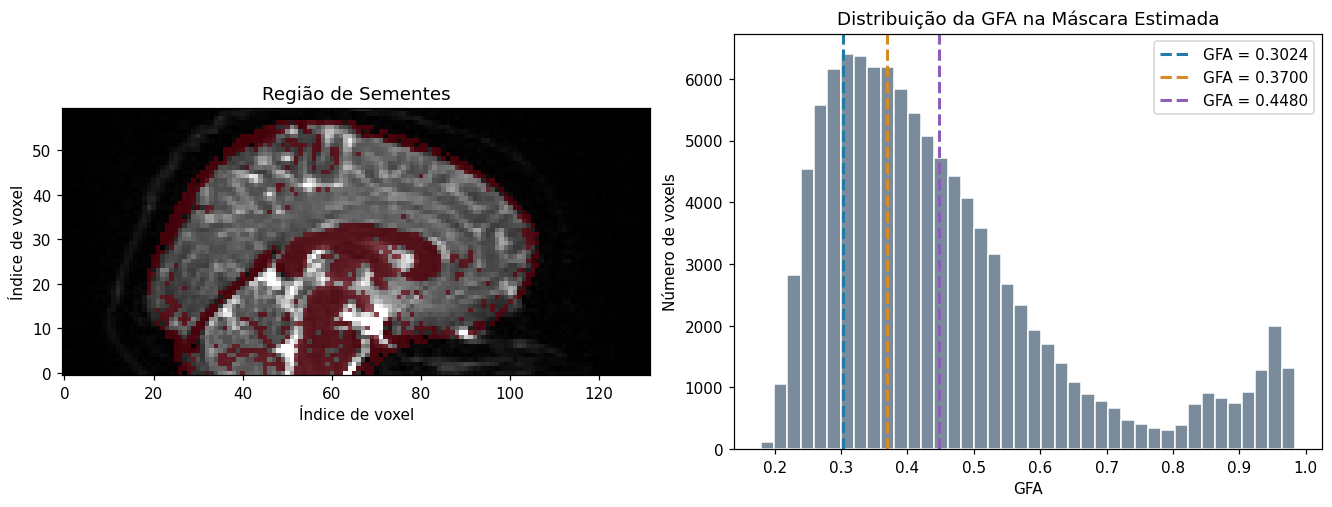

In [6]:
x_roi = int(np.median(np.where(brain_mask)[eixo_lr]))
forma = [1, 1, 1]
forma[eixo_lr] = b0.shape[eixo_lr]
coordenada_lr = np.arange(b0.shape[eixo_lr]).reshape(forma)

seed_mask = white_matter & (np.abs(coordenada_lr - x_roi) <= 2)
if seed_mask.sum() < 10:
    seed_mask = white_matter & (np.abs(coordenada_lr - x_roi) <= 4)

seeds = np.asarray(utils.seeds_from_mask(seed_mask, affine, density=DENSIDADE_SEMENTES))
if len(seeds) > MAX_SEMENTES:
    rng = np.random.default_rng(SEMENTE_ALEATORIA)
    seeds = seeds[rng.choice(len(seeds), size=MAX_SEMENTES, replace=False)]

print(f"Número de sementes: {len(seeds)}")
print(f"Limiares GFA: {LIMIARES_GFA}")
print(f"Passo: {PASSO_MM} mm | Ângulo máximo: {ANGULO_MAX_GRAUS}°")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

axes[0].imshow(np.take(b0, x_roi, axis=eixo_lr).T, cmap="gray", origin="lower", vmin=0, vmax=intensidade_max)
axes[0].imshow(np.ma.masked_equal(np.take(seed_mask, x_roi, axis=eixo_lr).T, 0), cmap="Reds", origin="lower", vmin=0, vmax=1, alpha=0.65)
axes[0].set_title("Região de Sementes")
axes[0].set_xlabel("Índice de voxel")
axes[0].set_ylabel("Índice de voxel")

axes[1].hist(valores_gfa, bins=40, color="#7a8c9c", edgecolor="white")

for limiar in LIMIARES_GFA:
    axes[1].axvline(limiar, color=CORES_LIMIARES[limiar], linestyle="--", linewidth=2, label=f"GFA = {limiar:.4f}")

axes[1].set_title("Distribuição da GFA na Máscara Estimada")
axes[1].set_xlabel("GFA")
axes[1].set_ylabel("Número de voxels")
axes[1].legend()

plt.show()

## **Reconstrução das Trajetórias por Tractografia**

- Aplicação do algoritmo de tractografia EuDX para reconstruir trajetórias da substância branca com diferentes limiares de GFA, filtrar as trajetórias pelo comprimento e comparar os resultados obtidos.

In [7]:
resultados = []
tracks_por_limiar = {}
comprimentos_por_limiar = {}

for limiar in LIMIARES_GFA:

    criterio = ThresholdStoppingCriterion(gfa, limiar)

    brutas = Streamlines(eudx_tracking(seeds, criterio, affine, pam=csa_peaks, step_size=PASSO_MM, max_cross=1, max_angle=ANGULO_MAX_GRAUS, random_seed=SEMENTE_ALEATORIA, nbr_threads=1))

    comprimentos = np.array([length(track) for track in brutas])
    validas = (comprimentos >= COMPRIMENTO_MIN_MM) & (comprimentos <= COMPRIMENTO_MAX_MM)

    retidas = Streamlines([track for track, valido in zip(brutas, validas) if valido])
    comprimentos_retidos = comprimentos[validas]

    tracks_por_limiar[limiar] = retidas
    comprimentos_por_limiar[limiar] = comprimentos_retidos

    if len(comprimentos_retidos) > 0:
        media = np.mean(comprimentos_retidos)
        mediana = np.median(comprimentos_retidos)
        q1, q3 = np.percentile(comprimentos_retidos, [25, 75])
        iqr = q3 - q1
    else:
        media = mediana = iqr = np.nan

    resultados.append({"limiar_GFA": limiar, "n_sementes": len(seeds), "n_trajetorias_brutas": len(brutas), "n_trajetorias_retidas": len(retidas), "percentagem_retidas": 100 * len(retidas) / len(brutas) if len(brutas) else 0, "comprimento_medio_mm": media, "comprimento_mediano_mm": mediana, "iqr_comprimento_mm": iqr})

df = pd.DataFrame(resultados)
display(df.round(3))

,limiar_GFA,n_sementes,n_trajetorias_brutas,n_trajetorias_retidas,percentagem_retidas,comprimento_medio_mm,comprimento_mediano_mm,iqr_comprimento_mm
0,0.302,400,277,143,51.625,48.608,35.50,59.250
1,0.370,400,207,100,48.309,40.055,34.25,42.625
2,0.448,400,161,64,39.752,31.469,27.50,25.125


## **Análise e Comparação dos Resultados da Tractografia**

- Comparação do número de trajetórias reconstruídas e retidas para cada limiar de GFA, análise da distribuição dos seus comprimentos e cálculo da variação percentual das trajetórias retidas.

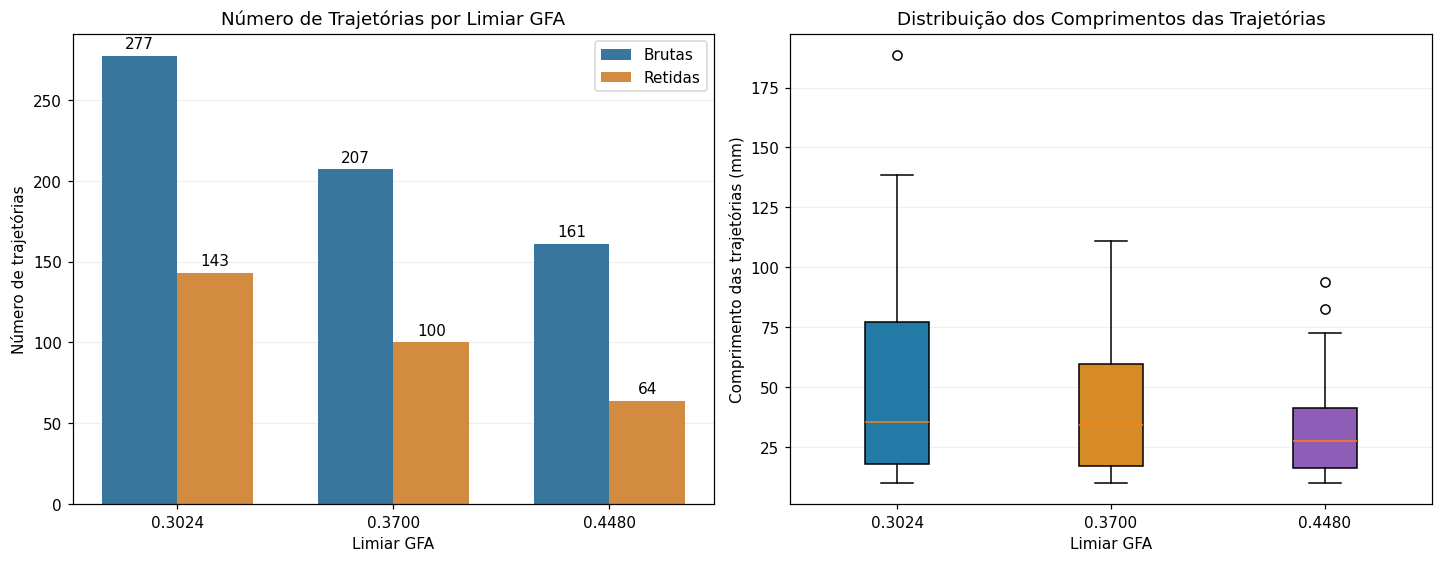

Variação das trajetórias retidas: -55.2%


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

posicoes = np.arange(len(LIMIARES_GFA))
largura = 0.35
nomes_limiares = [f"{limiar:.4f}" for limiar in LIMIARES_GFA]

brutas = axes[0].bar(posicoes - largura/2, df["n_trajetorias_brutas"], largura, color="#38769d", label="Brutas")
retidas = axes[0].bar(posicoes + largura/2, df["n_trajetorias_retidas"], largura, color="#d28b3f", label="Retidas")

axes[0].bar_label(brutas, padding=3)
axes[0].bar_label(retidas, padding=3)
axes[0].set_xticks(posicoes, nomes_limiares)
axes[0].set_xlabel("Limiar GFA")
axes[0].set_ylabel("Número de trajetórias")
axes[0].set_title("Número de Trajetórias por Limiar GFA")
axes[0].legend()

comprimentos = [comprimentos_por_limiar[limiar] if len(comprimentos_por_limiar[limiar]) else [np.nan] for limiar in LIMIARES_GFA]

bp = axes[1].boxplot(comprimentos, patch_artist=True)
for caixa, limiar in zip(bp["boxes"], LIMIARES_GFA):
    caixa.set_facecolor(CORES_LIMIARES[limiar])

axes[1].set_xticks(posicoes + 1, nomes_limiares)
axes[1].set_xlabel("Limiar GFA")
axes[1].set_ylabel("Comprimento das trajetórias (mm)")
axes[1].set_title("Distribuição dos Comprimentos das Trajetórias")

for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

plt.show()

n_inicio = df["n_trajetorias_retidas"].iloc[0]
n_fim = df["n_trajetorias_retidas"].iloc[-1]

if n_inicio > 0:
    variacao = 100 * (n_fim - n_inicio) / n_inicio
    print(f"Variação das trajetórias retidas: {variacao:+.1f}%")

## **Visualização 3D das Trajetórias da Substância Branca**

- Representação tridimensional das trajetórias reconstruídas para os três limiares de GFA, permitindo comparar visualmente a quantidade, a distribuição espacial e a orientação das trajetórias.

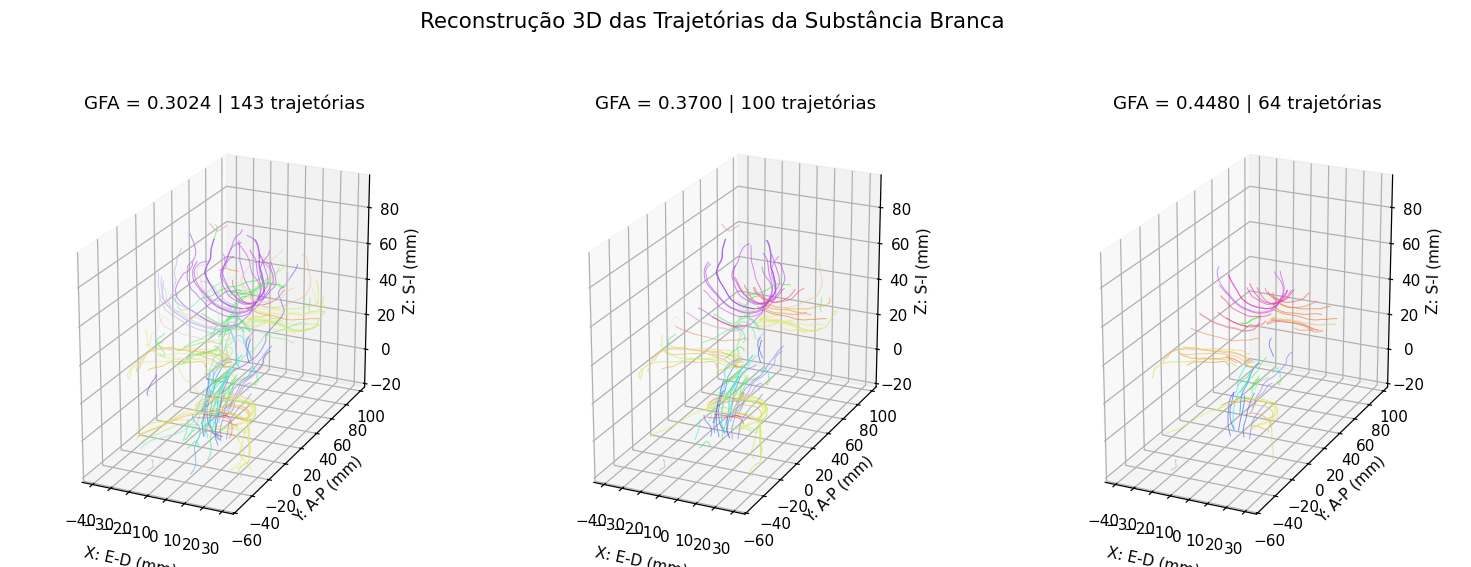

In [9]:
def cor_orientacao(track):
    direcoes = np.abs(np.diff(track, axis=0))
    orientacao = np.mean(direcoes, axis=0)
    return 0.12 + 0.80 * orientacao / max(np.max(orientacao), 1e-9)


todas_as_trajetorias = [np.asarray(track) for limiar in LIMIARES_GFA for track in tracks_por_limiar[limiar]]

coordenadas = np.concatenate(todas_as_trajetorias) if todas_as_trajetorias else seeds
minimos = coordenadas.min(axis=0) - 3
maximos = coordenadas.max(axis=0) + 3

fig = plt.figure(figsize=(17, 6))

for i, limiar in enumerate(LIMIARES_GFA, start=1):

    ax = fig.add_subplot(1, 3, i, projection="3d")
    tracks = tracks_por_limiar[limiar]

    for track in tracks:
        ax.plot(track[:, 0], track[:, 1], track[:, 2], color=cor_orientacao(track), linewidth=0.65, alpha=0.65)

    ax.set_title(f"GFA = {limiar:.4f} | {len(tracks)} trajetórias")
    ax.set_xlabel("X: E-D (mm)")
    ax.set_ylabel("Y: A-P (mm)")
    ax.set_zlabel("Z: S-I (mm)")

    ax.set_xlim(minimos[0], maximos[0])
    ax.set_ylim(minimos[1], maximos[1])
    ax.set_zlim(minimos[2], maximos[2])
    ax.set_box_aspect(maximos - minimos)
    ax.view_init(elev=22, azim=-65)

fig.suptitle("Reconstrução 3D das Trajetórias da Substância Branca", fontsize=14)
plt.show()

## **Visualização Interativa 3D da Tractografia**

- Visualização interativa das trajetórias reconstruídas com o limiar de GFA de referência, permitindo explorar a sua orientação espacial, os cortes de MRI e a localização das sementes.

In [10]:
import plotly.graph_objects as go
from scipy.ndimage import binary_dilation, binary_closing, binary_fill_holes, label

tracks_ref = tracks_por_limiar[LIMIAR_REFERENCIA]
fig3d = go.Figure()

mascara_cerebro = binary_dilation(brain_mask, iterations=3)

def adicionar_corte(plano, visivel):

    eixo = eixo_lr if plano == "Sagital" else eixo_si
    indice = x_roi if plano == "Sagital" else zi
    corte = np.take(b0, indice, axis=eixo)
    mascara = np.take(mascara_cerebro, indice, axis=eixo)

    grelha = np.indices(corte.shape)
    indices = np.zeros(corte.shape + (3,), dtype=int)
    eixos_restantes = [i for i in range(3) if i != eixo]
    for i, eixo_restante in enumerate(eixos_restantes):
        indices[..., eixo_restante] = grelha[i]
    indices[..., eixo] = indice

    mascara = mascara & (corte > 0.10 * intensidade_max)
    mascara = binary_closing(mascara, iterations=2)

    rotulos, numero = label(mascara)
    if numero > 0:
        areas = np.bincount(rotulos.ravel())
        areas[0] = 0
        mascara = binary_fill_holes(rotulos == np.argmax(areas))

    coordenadas = nib.affines.apply_affine(affine, indices)
    coordenadas[~mascara] = np.nan

    fig3d.add_trace(go.Surface(x=coordenadas[:, :, 0], y=coordenadas[:, :, 1], z=coordenadas[:, :, 2], surfacecolor=corte, colorscale=[[0, "black"], [1, "white"]], cmin=0, cmax=intensidade_max, opacity=0.65, showscale=False, showlegend=True, connectgaps=False, name=f"MRI — Corte {plano}", visible=visivel))


adicionar_corte("Sagital", True)
adicionar_corte("Axial", "legendonly")

linhas = [[[], [], []] for _ in range(3)]

for track in tracks_ref:
    pontos = np.asarray(track)[::2]

    for i in range(len(pontos) - 1):
        p1, p2 = pontos[i], pontos[i + 1]
        eixo = np.argmax(np.abs(p2 - p1))

        linhas[eixo][0].extend([p1[0], p2[0], None])
        linhas[eixo][1].extend([p1[1], p2[1], None])
        linhas[eixo][2].extend([p1[2], p2[2], None])

nomes = ["Esquerda-Direita", "Anterior-Posterior", "Superior-Inferior"]
cores = ["#d44854", "#209b6f", "#3b6dd8"]

for i in range(3):
    fig3d.add_trace(go.Scatter3d(x=linhas[i][0], y=linhas[i][1], z=linhas[i][2], mode="lines", line=dict(color=cores[i], width=2.5), name=nomes[i]))


fig3d.add_trace(go.Scatter3d(x=seeds[:, 0], y=seeds[:, 1], z=seeds[:, 2], mode="markers", marker=dict(size=2.5, color="yellow"), name=f"Sementes ({len(seeds)})", visible="legendonly"))

fig3d.update_layout(title=f"Tractografia 3D — GFA = {LIMIAR_REFERENCIA:.4f} ({len(tracks_ref)} trajetórias)", height=750, scene=dict(xaxis_title="X (mm)", yaxis_title="Y (mm)", zaxis_title="Z (mm)", aspectmode="data", camera=dict(eye=dict(x=1.65, y=-1.55, z=1.05))))

fig3d.show()

---

**DIPY Estudo | "The energetic costs of the human connectome"**


> <small> **Referências:** 
</strong> Castrillon <em>et al.</em> (2023). <em>An energy costly architecture of neuromodulators for human brain evolution and cognition.</em> <em>Science Advances.</em><br>
<a href="https://doi.org/10.1126/sciadv.adi7632">Artigo Científico (DOI)</a> |
<a href="https://openneuro.org/datasets/ds004513">Dataset (ds004513)</a> |
<a href="https://github.com/NeuroenergeticsLab/energetic_costs">Repositório dos Autores (GitHub)</a>
</small>